# 🛸 OpenDarkSTS — YOLOv8 Training Notebook
Train a YOLOv8l model to detect dark fleet Ship-to-Ship (STS) transfers from Sentinel-2 satellite imagery.

**Classes:**
- `ship` (0) — Normal vessel with AIS signal
- `ships` (1) — STS transfer / dark fleet activity

**Pipeline:** Polygon labels → Bounding boxes → Train → Evaluate → Deploy to GUI

## 📦 Step 1 — Install Dependencies

In [1]:
# Install required packages
!pip install ultralytics opencv-python matplotlib seaborn torch torchvision --quiet
print('✅ Dependencies installed')

✅ Dependencies installed


## ⚙️ Step 2 — Configuration
**Update these paths to match your system**

In [2]:
from pathlib import Path
import torch

# ── UPDATE THESE PATHS ────────────────────────────────────────
DATA_DIR    = Path(r"C:\Users\Lenovo\Documents\data science project\data science dark fleet.v7i.yolov8 (1)")
YAML_PATH   = DATA_DIR / "dataset.yaml"
RUNS_DIR    = DATA_DIR / "runs"
RUN_NAME    = "dark_fleet_yolov8l"
WEIGHTS_DIR = RUNS_DIR / RUN_NAME / "weights"

# ── NEW BASE WEIGHTS (YOLOv8n pretrained) ─────────────────────
NEW_WEIGHTS = Path(r"C:\Users\Lenovo\Documents\OpenDarkSTS\new2026\yolov8n_rectbbox_e150_img960\yolov8n_rectbbox_e150_img960\weights\best.pt")

# ── TRAINING CONFIG ───────────────────────────────────────────
EPOCHS        = 300
IMGSZ         = 1280
BATCH         = 4      # safe for 12GB VRAM
DEVICE        = "0" if torch.cuda.is_available() else "cpu"
BASE_MODEL    = str(NEW_WEIGHTS) if NEW_WEIGHTS.exists() else "yolov8l.pt"

# ── CHECK GPU ────────────────────────────────────────────────
print(f"GPU available : {torch.cuda.is_available()}")
print(f"GPU name      : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only'}")
print(f"VRAM          : {torch.cuda.get_device_properties(0).total_memory // 1024**3 if torch.cuda.is_available() else 0}GB")
print(f"Device        : {DEVICE}")
print(f"\nData dir      : {DATA_DIR}")
print(f"YAML exists   : {YAML_PATH.exists()}")
print(f"Runs dir      : {RUNS_DIR}")
print(f"\nNew weights   : {NEW_WEIGHTS}")
print(f"Weights exist : {NEW_WEIGHTS.exists()}")
print(f"Base model    : {BASE_MODEL}")

GPU available : True
GPU name      : NVIDIA GeForce RTX 5070 Ti Laptop GPU
VRAM          : 11GB
Device        : 0

Data dir      : C:\Users\Lenovo\Documents\data science project\data science dark fleet.v7i.yolov8 (1)
YAML exists   : True
Runs dir      : C:\Users\Lenovo\Documents\data science project\data science dark fleet.v7i.yolov8 (1)\runs

New weights   : C:\Users\Lenovo\Documents\OpenDarkSTS\new2026\yolov8n_rectbbox_e150_img960\yolov8n_rectbbox_e150_img960\weights\best.pt
Weights exist : True
Base model    : C:\Users\Lenovo\Documents\OpenDarkSTS\new2026\yolov8n_rectbbox_e150_img960\yolov8n_rectbbox_e150_img960\weights\best.pt


## 🔄 Step 3 — Convert Polygon Labels to Bounding Boxes
Roboflow exports polygon/segmentation masks — we convert them to YOLO bounding boxes before training.

In [3]:
LABEL_DIRS = [
    DATA_DIR / "train" / "labels",
    DATA_DIR / "valid" / "labels",
    DATA_DIR / "test"  / "labels",
]

converted = 0
skipped   = 0

for label_dir in LABEL_DIRS:
    if not label_dir.exists():
        print(f"⚠️  Not found: {label_dir}")
        continue

    for txt_file in label_dir.glob("*.txt"):
        lines     = txt_file.read_text().splitlines()
        new_lines = []
        changed   = False

        for line in lines:
            parts = line.strip().split()
            if not parts:
                continue
            cls_id = parts[0]
            coords = list(map(float, parts[1:]))

            if len(coords) == 4:
                new_lines.append(line)
                continue

            if len(coords) >= 6 and len(coords) % 2 == 0:
                xs = coords[0::2]
                ys = coords[1::2]
                cx = (min(xs) + max(xs)) / 2
                cy = (min(ys) + max(ys)) / 2
                w  = max(xs) - min(xs)
                h  = max(ys) - min(ys)
                new_lines.append(f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
                changed = True
            else:
                new_lines.append(line)

        if changed:
            txt_file.write_text("\n".join(new_lines) + "\n")
            converted += 1
        else:
            skipped += 1

print(f"✅ Converted : {converted} label files (polygon → bbox)")
print(f"   Unchanged : {skipped} label files (already bounding boxes)")

✅ Converted : 0 label files (polygon → bbox)
   Unchanged : 381 label files (already bounding boxes)


## 🔍 Step 4 — Preview Annotations
Visualise bounding boxes on random training images before training.

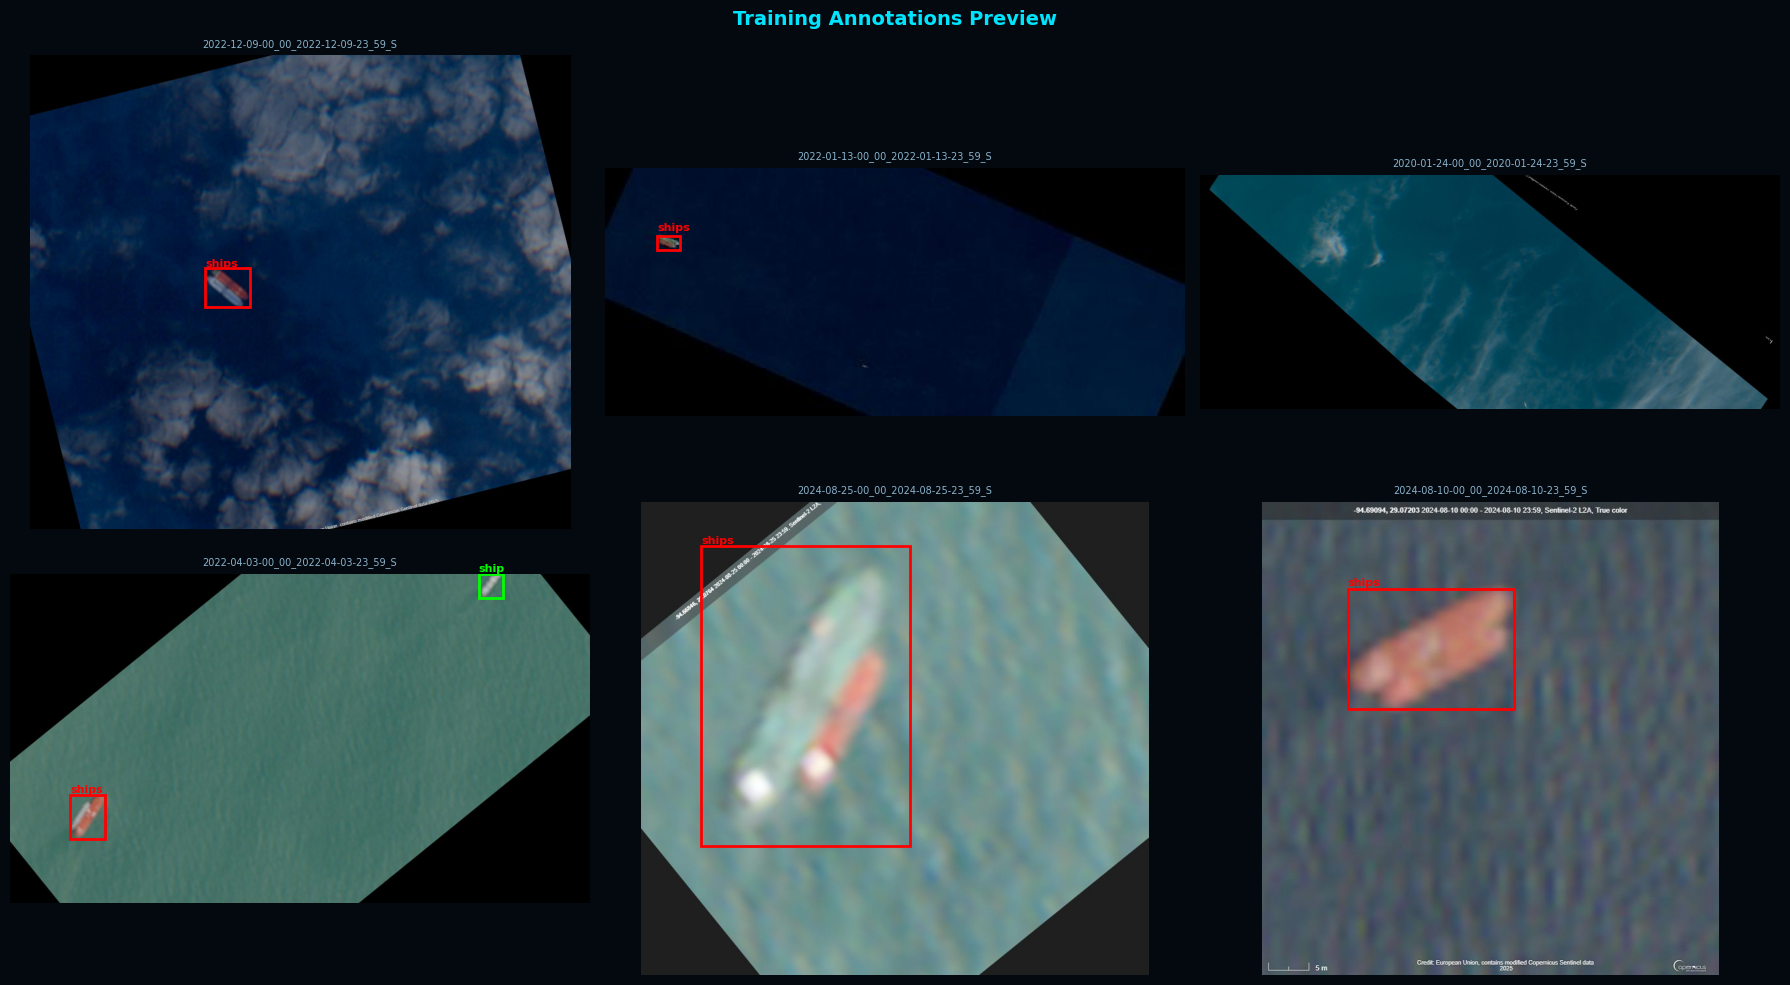

✅ Preview saved as annotation_preview.png


In [4]:
import cv2
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

IMAGE_DIR   = DATA_DIR / "train" / "images"
LABEL_DIR   = DATA_DIR / "train" / "labels"
CLASS_NAMES = ["ship", "ships"]
COLORS      = [(0, 200, 0), (255, 50, 50)]  # green=ship, red=ships
NUM_SAMPLES = 6

image_files = sorted(IMAGE_DIR.glob("*.jpg")) + sorted(IMAGE_DIR.glob("*.png"))
samples     = random.sample(image_files, min(NUM_SAMPLES, len(image_files)))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor('#04080f')

for ax, img_path in zip(axes.flatten(), samples):
    lbl_path = LABEL_DIR / (img_path.stem + ".txt")
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    ax.imshow(img)
    ax.set_facecolor('#04080f')
    ax.set_title(img_path.name[:35], color='#8ab4cc', fontsize=7)
    ax.axis('off')

    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls_id = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:])
            x1 = (cx - bw/2) * w
            y1 = (cy - bh/2) * h
            color = ['lime', 'red'][min(cls_id, 1)]
            label = CLASS_NAMES[cls_id] if cls_id < len(CLASS_NAMES) else str(cls_id)
            rect = patches.Rectangle((x1, y1), bw*w, bh*h,
                                       linewidth=2, edgecolor=color, facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, y1-4, label, color=color, fontsize=8, fontweight='bold')

plt.suptitle('Training Annotations Preview', color='#00e5ff', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('annotation_preview.png', dpi=100, bbox_inches='tight', facecolor='#04080f')
plt.show()
print('✅ Preview saved as annotation_preview.png')

## 🏋️ Step 5 — Train Model
Train YOLOv8l with corrected bounding boxes at 1280px resolution.

In [5]:
from ultralytics import YOLO

# Load base model or resume from existing weights
weights = str(WEIGHTS_DIR / "best.pt") if (WEIGHTS_DIR / "best.pt").exists() else BASE_MODEL
print(f"Loading weights from: {weights}")

model = YOLO(weights)

results = model.train(
    data          = str(YAML_PATH),
    epochs        = EPOCHS,
    imgsz         = IMGSZ,
    batch         = BATCH,
    patience      = 0,           # train all epochs
    device        = DEVICE,
    workers       = 0,           # required for Windows
    exist_ok      = True,
    name          = RUN_NAME,
    project       = str(RUNS_DIR),

    # Learning rate
    lr0           = 0.0005,
    lrf           = 0.001,
    warmup_epochs = 10,
    cos_lr        = True,

    # Augmentation
    degrees       = 90.0,
    flipud        = 0.5,
    fliplr        = 0.5,
    mosaic        = 1.0,
    scale         = 0.7,
    translate     = 0.2,
    shear         = 5.0,
    mixup         = 0.1,
    copy_paste    = 0.1,

    # Save
    plots         = True,
    save          = True,
    save_period   = 20,
    verbose       = True,
)

print("\n✅ Training complete!")
print(f"Best weights: {WEIGHTS_DIR / 'best.pt'}")

Loading weights from: C:\Users\Lenovo\Documents\data science project\data science dark fleet.v7i.yolov8 (1)\runs\dark_fleet_yolov8l\weights\best.pt
New https://pypi.org/project/ultralytics/8.4.46 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.23  Python-3.10.20 torch-2.10.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Ti Laptop GPU, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Lenovo\Documents\data science project\data science dark fleet.v7i.yolov8 (1)\dataset.yaml, degrees=90.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s

AcceleratorError: CUDA error: an illegal memory access was encountered
Search for `cudaErrorIllegalAddress' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


## 📊 Step 6 — Evaluate on Test Set

In [ ]:
from ultralytics import YOLO

best_model = YOLO(str(WEIGHTS_DIR / "best.pt"))

metrics = best_model.val(
    data    = str(YAML_PATH),
    split   = "test",
    imgsz   = IMGSZ,
    device  = DEVICE,
    workers = 0,
    plots   = True,
)

box = metrics.box
print("\n📊 Test Set Results:")
print(f"  mAP50     : {box.map50:.4f}")
print(f"  mAP50-95  : {box.map:.4f}")
print(f"  Precision : {box.mp:.4f}")
print(f"  Recall    : {box.mr:.4f}")

## 🔭 Step 7 — Test on Individual Images

In [ ]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

model       = YOLO(str(WEIGHTS_DIR / "best.pt"))
TEST_DIR    = DATA_DIR / "test" / "images"
CLASS_NAMES = ["ship", "ships"]
CONF_THRESH = 0.10

test_images = sorted(TEST_DIR.glob("*.jpg"))[:6]
fig, axes   = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor('#04080f')

for ax, img_path in zip(axes.flatten(), test_images):
    results = model.predict(source=str(img_path), conf=CONF_THRESH, verbose=False)
    r       = results[0]
    img     = cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)

    sts_count   = sum(1 for b in r.boxes if int(b.cls[0]) == 1)
    ship_count  = sum(1 for b in r.boxes if int(b.cls[0]) == 0)

    ax.imshow(img)
    ax.set_facecolor('#04080f')
    title_color = 'red' if sts_count > 0 else 'lime'
    ax.set_title(f"{img_path.name[:30]}\nships(STS)={sts_count} ship={ship_count}",
                 color=title_color, fontsize=7)
    ax.axis('off')

plt.suptitle(f'Test Predictions (conf≥{CONF_THRESH})', color='#00e5ff', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('test_predictions.png', dpi=100, bbox_inches='tight', facecolor='#04080f')
plt.show()
print('✅ Saved as test_predictions.png')

## 🚀 Step 8 — Deploy to GUI
Copy the new weights to your GUI app location.

In [ ]:
import shutil

best_pt = WEIGHTS_DIR / "best.pt"

print(f"📦 Base weights used for training:")
print(f"   {NEW_WEIGHTS}")
print(f"   Exists: {NEW_WEIGHTS.exists()}")
print()

if best_pt.exists():
    size_mb = best_pt.stat().st_size / 1024**2
    print(f"✅ Trained weights ready:")
    print(f"   {best_pt}")
    print(f"   Size: {size_mb:.1f} MB")
    print(f"\n🚀 To use in GUI update app.py:")
    print(f"   BEST_WEIGHTS = Path(r'{best_pt}')")
    print(f"\n   Then restart Flask: python app.py")
    print(f"   Open: http://localhost:5000")
else:
    print("❌ No trained weights found — run training first (Step 5)")
    print(f"   Expected at: {best_pt}")

## 📈 Step 9 — Plot Training Results

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results_csv = RUNS_DIR / RUN_NAME / "results.csv"

if results_csv.exists():
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.patch.set_facecolor('#04080f')

    plots = [
        ('metrics/mAP50(B)',    'mAP50',      '#00e5ff'),
        ('metrics/mAP50-95(B)', 'mAP50-95',   '#00ff88'),
        ('metrics/precision(B)','Precision',  '#ffaa00'),
        ('metrics/recall(B)',   'Recall',     '#ff2244'),
        ('train/box_loss',      'Train Box Loss', '#8888ff'),
        ('val/box_loss',        'Val Box Loss',   '#ff88ff'),
    ]

    for ax, (col, title, color) in zip(axes.flatten(), plots):
        if col in df.columns:
            ax.plot(df[col], color=color, linewidth=1.5)
            ax.set_facecolor('#080f1c')
            ax.set_title(title, color='#8ab4cc', fontsize=11)
            ax.tick_params(colors='#3a5570')
            ax.spines[:].set_color('#112030')
            ax.grid(True, color='#112030', alpha=0.5)

    plt.suptitle('Training Progress', color='#00e5ff', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('training_results.png', dpi=100, bbox_inches='tight', facecolor='#04080f')
    plt.show()
    print('✅ Saved as training_results.png')
else:
    print('⚠️ No results.csv found — run training first')